<a href="https://colab.research.google.com/github/Ahmed-log11/Pair_Challenge/blob/main/Ahmed_Razan_Olympic_pair_challenge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[Data in Kaggle](https://www.kaggle.com/heesoo37/120-years-of-olympic-history-athletes-and-results?select=athlete_events.csv)

# Import the libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Read the data

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("heesoo37/120-years-of-olympic-history-athletes-and-results")

print("Path to dataset files:", path)
df = pd.read_csv(path + "/athlete_events.csv")
df.head()

Using Colab cache for faster access to the '120-years-of-olympic-history-athletes-and-results' dataset.
Path to dataset files: /kaggle/input/120-years-of-olympic-history-athletes-and-results


,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


### Don't forget to drop duplicates first

In [4]:
df = df.drop_duplicates()
df.shape

(269731, 15)

# <font color='red'>**Beginner level**</font>

### Find the missing data in each column

In [5]:
df.isnull().sum()

,0
ID,0
Name,0
Sex,0
Age,9315
Height,58814
Weight,61527
Team,0
NOC,0
Games,0
Year,0


### Number of males and females

In [6]:
df.drop_duplicates("ID")["Sex"].value_counts()

,count
Sex,
M,101590
F,33981


### How many cities do we have and what are they ?

In [7]:
print(df["City"].nunique())
print(df["City"].unique())

42
['Barcelona' 'London' 'Antwerpen' 'Paris' 'Calgary' 'Albertville'
 'Lillehammer' 'Los Angeles' 'Salt Lake City' 'Helsinki' 'Lake Placid'
 'Sydney' 'Atlanta' 'Stockholm' 'Sochi' 'Nagano' 'Torino' 'Beijing'
 'Rio de Janeiro' 'Athina' 'Squaw Valley' 'Innsbruck' 'Sarajevo'
 'Mexico City' 'Munich' 'Seoul' 'Berlin' 'Oslo' "Cortina d'Ampezzo"
 'Melbourne' 'Roma' 'Amsterdam' 'Montreal' 'Moskva' 'Tokyo' 'Vancouver'
 'Grenoble' 'Sapporo' 'Chamonix' 'St. Louis' 'Sankt Moritz'
 'Garmisch-Partenkirchen']


# <font color='red'>**Intermediate level**</fond>

### Find the number of athlete for each year

In [8]:
df.groupby("Year")["ID"].nunique()

,ID
Year,
1896,176
1900,1224
1904,650
1906,841
1908,2024
1912,2409
1920,2676
1924,3565
1928,3703


### Which athlete participated the most? (his/her name and ID)

In [11]:
df.groupby(["ID", "Name"]).size().sort_values(ascending=False).head(1)

,,0
ID,Name,
106296,Heikki Ilmari Savolainen,39


# <font color='red'>**Advanced level**</fond>

### Find the number of each medal for each year.
##### The output should look like this
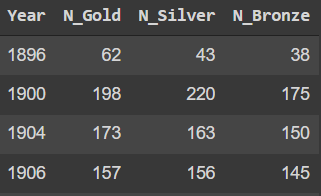

In [12]:
pd.crosstab(df["Year"], df["Medal"])

Medal,Bronze,Gold,Silver
Year,,,
1896,38,62,43
1900,175,198,220
1904,150,173,163
1906,145,157,156
1908,256,294,281
1912,300,326,315
1920,367,493,448
1924,311,332,319
1928,281,275,267


# <font color='red'>**You are Geek!**</fond>
### Provide all your answers with plots

### Find the number of winners with the gold medal in each city?

In [13]:
gold = df[df["Medal"] == "Gold"]
gold_city = gold.groupby("City")["ID"].nunique().sort_values(ascending=False)
gold_city

,ID
City,
London,1129
Athina,802
Los Angeles,659
Beijing,629
Rio de Janeiro,618
Sydney,615
Atlanta,568
Barcelona,515
Seoul,469


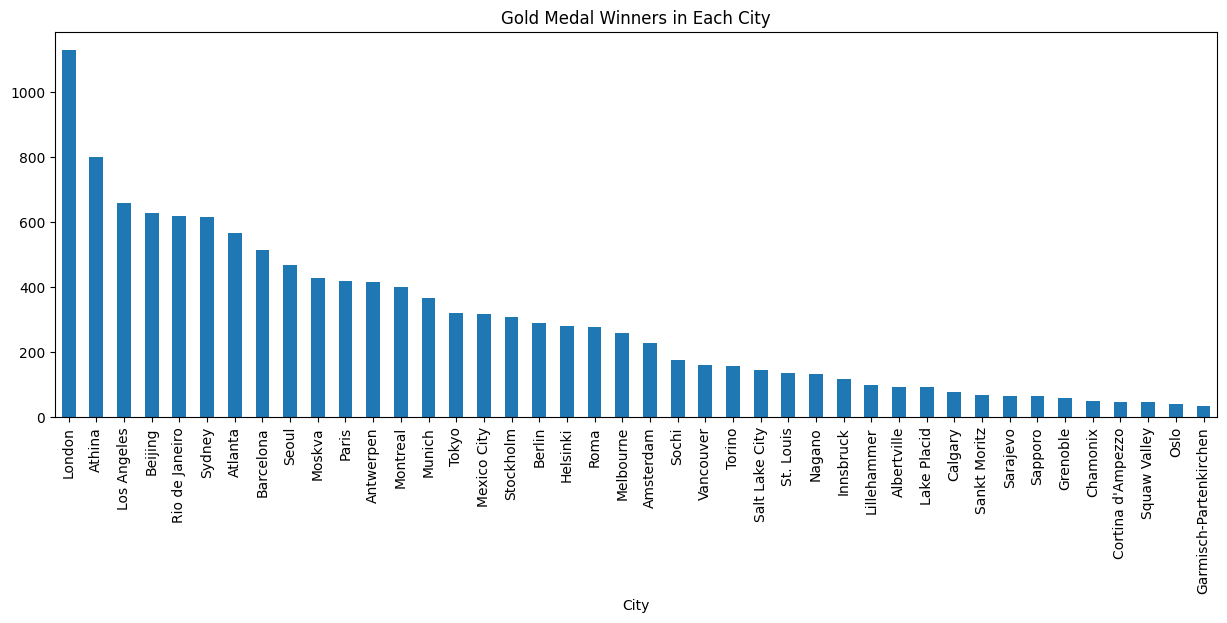

In [14]:
gold_city.plot(kind="bar", figsize=(15, 5), title="Gold Medal Winners in Each City")
plt.show()

### Find the total missing data for each year?

In [15]:
missing_year = df.isnull().groupby(df["Year"]).sum().sum(axis=1)
missing_year

,0
Year,
1896,1065
1900,5676
1904,3331
1906,5022
1908,8057
1912,10018
1920,11175
1924,15194
1928,14124


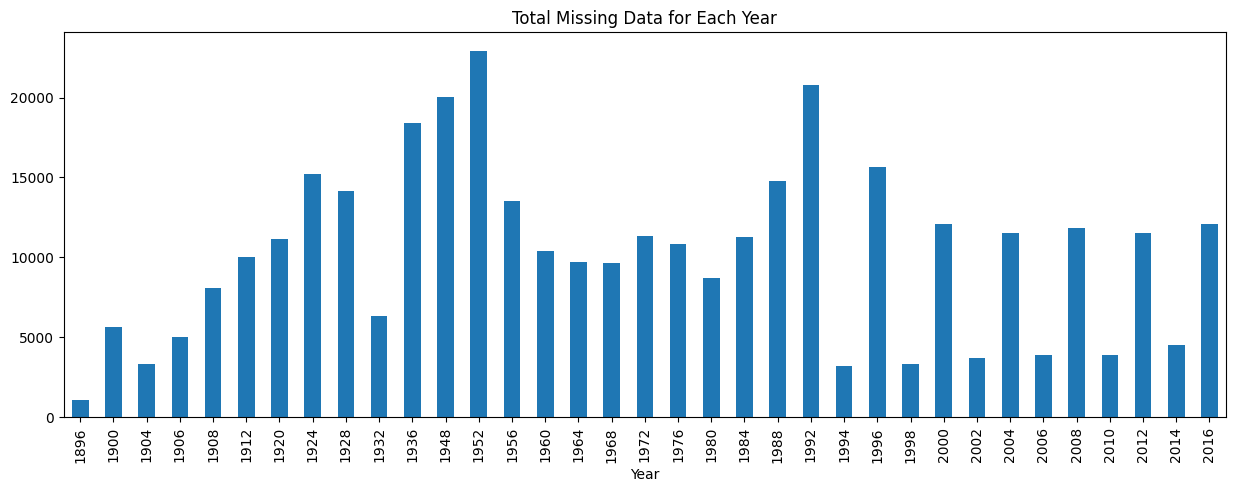

In [16]:
missing_year.plot(kind="bar", figsize=(15, 5), title="Total Missing Data for Each Year")
plt.show()

# <font color='red'>**I dare you to solve this :)**</fond>
### Dont use for loops, and provide all your answers with plots.

### Has the number of athletes changed over time for Summer and Winter?

In [ ]:
athletes = df.groupby(["Year", "Season"])["ID"].nunique().unstack()
athletes

Season,Summer,Winter
Year,,
1896,176.0,NaN
1900,1224.0,NaN
1904,650.0,NaN
1906,841.0,NaN
1908,2024.0,NaN
1912,2409.0,NaN
1920,2676.0,NaN
1924,3256.0,313.0
1928,3247.0,461.0


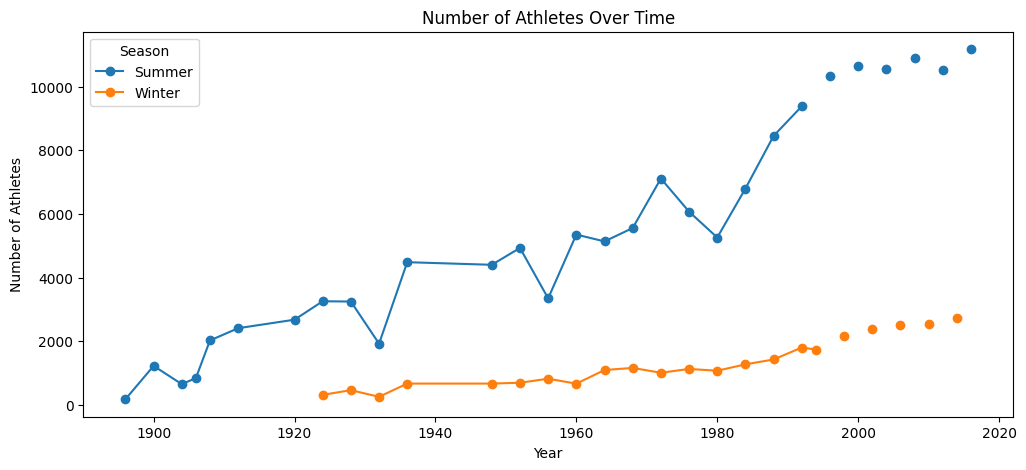

In [ ]:
athletes.plot(marker="o", figsize=(12, 5), title="Number of Athletes Over Time")
plt.ylabel("Number of Athletes")
plt.show()

Yes, the number of athletes changed over time. It increased a lot in both Summer and Winter Olympics, and the Summer Olympics always have many more athletes than the Winter Olympics.